# Relationality, per brain area → `figure_relationality_{AREA}.pdf`

[`../figure_4/figure_relationality.ipynb`](../figure_4/figure_relationality.ipynb),
once per recording area instead of pooled: the distribution of the relational-bias model's
fitted $\rho$ across neurons, one panel per monkey, one figure per area.

Nothing is refit. This reads the same cache the pooled figure reads and applies the same
selection — **within the area**. Which neurons are included is the shared, model-agnostic
2-object modulation criterion, so it is the same population the model comparison beside it
is drawn over.

$\rho = 0$ means the neuron measures object direction from **fixation**, $\rho = 1$ from the
**midpoint of the pair**. Both ends carry an **atom**: $\rho$ is
bounded to $[0, 1]$ because outside it the model is not identifiable, so a neuron whose
optimum sits on a bound lands exactly on it. Read the bars against 0 and 1 as counts of
neurons on a bound, not as a bin's worth of spread.

In [1]:
import matplotlib.pyplot as plt

import common
import relationality_lib as rl
import plot_lib

common.set_style()

# Only the metric's own model is drawn, but the set decides which neurons enter — it must
# contain `relational_bias`, or its fitted parameter is not in `summary`.
MODELS = ('future_field', 'relational_bias')
FIGSIZE = (5.2, 2.9)
N_BINS = 15
XLABEL = 'Relationality'

2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
FEF: 660 neurons enter the figure
DMFC: 679 neurons enter the figure
  Perle: 405 neurons with a fitted bias, median 0.55, 56 at 0, 2 at 1
  Elgar: 255 neurons with a fitted bias, median 0.50, 43 at 0, 1 at 1
saved figure_relationality_FEF.pdf


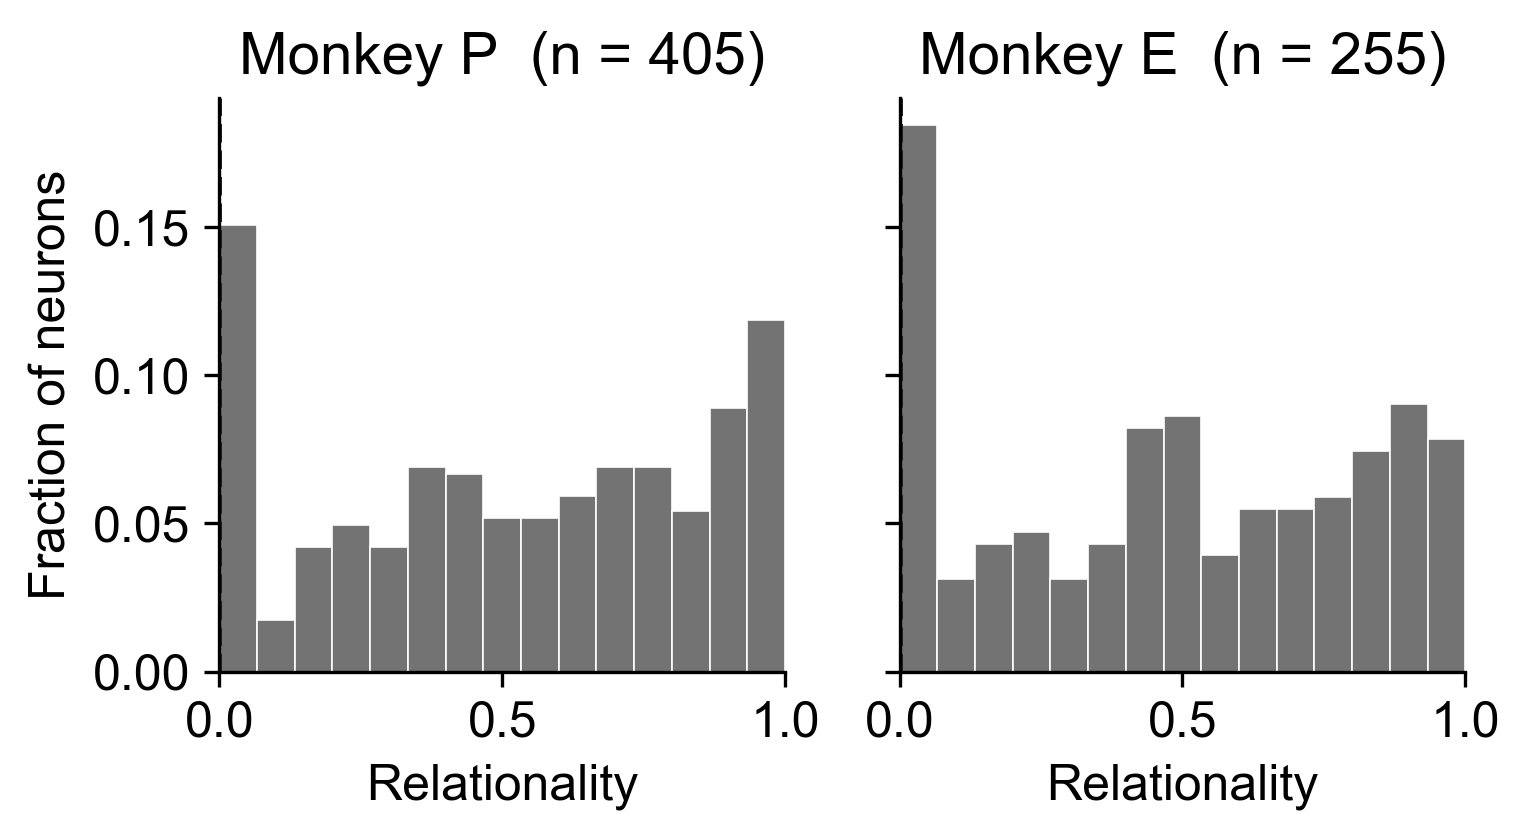

  Perle: 593 neurons with a fitted bias, median 0.74, 72 at 0, 1 at 1
  Elgar: 86 neurons with a fitted bias, median 0.67, 14 at 0, 0 at 1


saved figure_relationality_DMFC.pdf


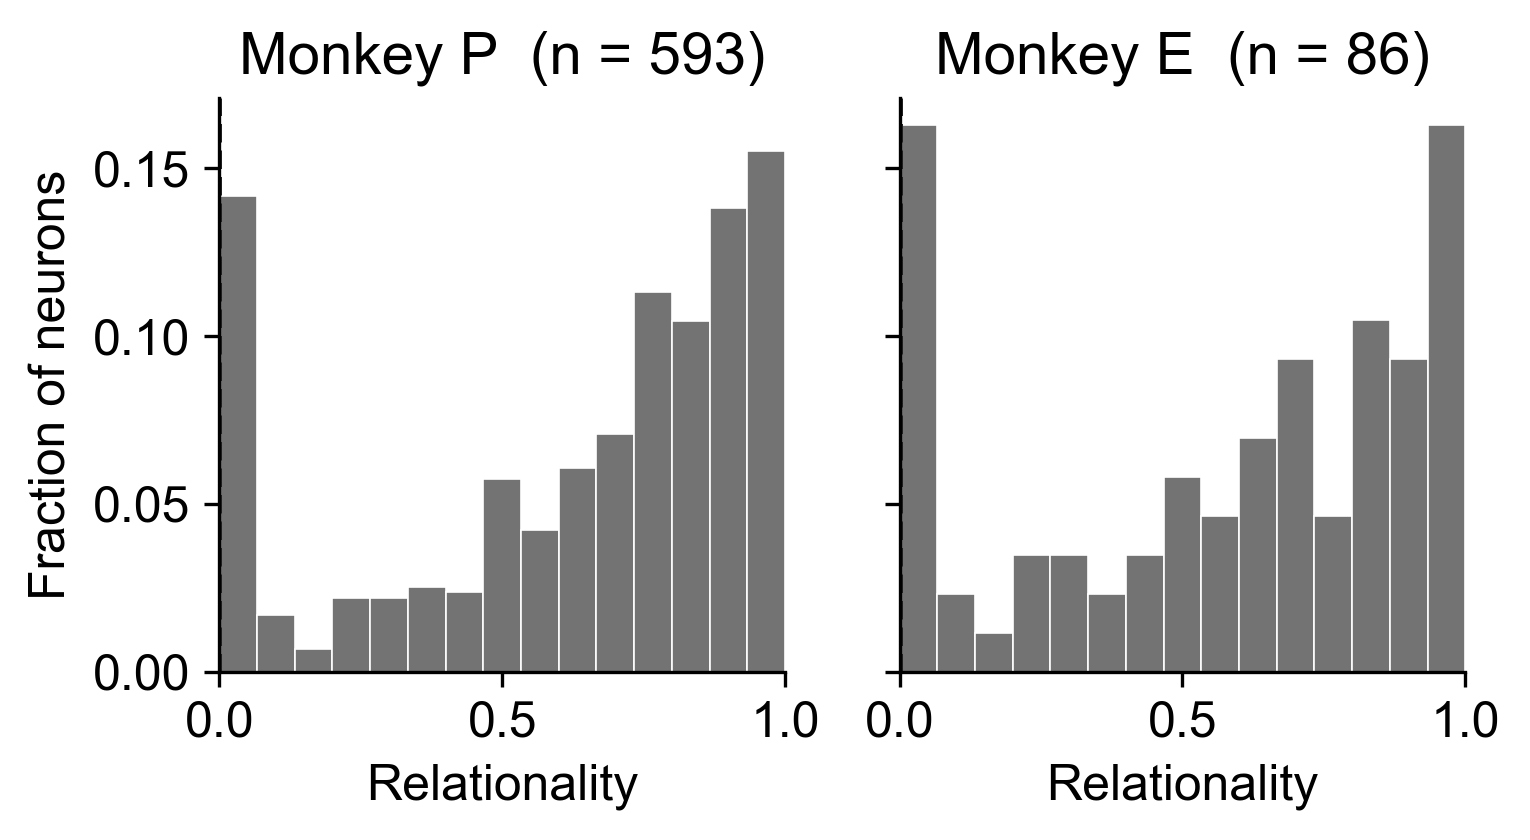

In [2]:
for area, summary in common.selected_fits_by_area(MODELS):
    biases = rl.biases(summary, verbose=False)
    for subject in plot_lib.levels(biases, 'subject'):
        v = biases[biases['subject'] == subject]['bias']
        print(f'  {subject}: {len(v)} neurons with a fitted bias, median {v.median():.2f}, '
              f'{int((v <= 1e-9).sum())} at 0, {int((v >= 1 - 1e-9).sum())} at 1')

    fig, _ = plot_lib.plot_relationality_distribution(
        biases, figsize=FIGSIZE, bins=N_BINS, xlabel=XLABEL)
    common.save(fig, f'figure_relationality_{area}.pdf')
    plt.show()